### Q5. Which brain area pair has the strongest undirected functional connectivity?

As in Q4, compute plain STTC with a 100 ms half-window on complete, simultaneously recorded spike trains. Compare the three unordered area pairs by forming every cross-area unit pair within each mouse. The mouse-specific observation window begins at the earliest spike and spans the LFP-derived recording duration. Launch Jupyter from the activated `con2phys` environment, then run `q5.r` after this notebook to fit the mixed model and select the Q5 answer.

In [1]:
import csv
import os
import sys
import time
from collections import defaultdict
from datetime import datetime
from itertools import combinations, product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sua_path = Path(os.environ.get(
    'Q5_SUA_CSV', 'E:/con2phys_submission/dataset/full_sua_dataset.csv'
))
output_dir = Path(os.environ.get(
    'Q5_OUTPUT_DIR', 'D:/git_repos/con2phys_submission/results/q5'
))
isttc_src = Path(os.environ.get('Q5_ISTTC_SRC', 'D:/intr_timescales/isttc/src'))
if isttc_src.is_dir():
    sys.path.insert(0, str(isttc_src))

from isttc.scripts.calculate_acf import (
    sttc, sttc_calculate_p_fast, sttc_calculate_t_fast,
)

DT = 0.100
N_MICE, N_UNITS = 18, 1449
AREAS = (1, 2, 3)
AREA_PAIRS = tuple(combinations(AREAS, 2))
PAIR_LABELS = [f'{a}-{b}' for a, b in AREA_PAIRS]
EXPECTED_COUNTS = dict(zip(PAIR_LABELS, [18560, 11598, 9167]))

#### Read and validate spike trains

Keep timestamps and the mouse window in floating-point seconds, including any valid negative timestamps. Check the total number of cross-area pairs against the counts derived from Q4's unit population.

In [2]:
units = defaultdict(dict)
durations = {}
first_spike = {}
last_spike = {}
seen_units = set()
required = {'mouse_id', 'cluster_id', 'brain_area', 'recording_duration_sec', 'n_spikes', 'spikes'}

csv.field_size_limit(2**31 - 1)
with sua_path.open(newline='', encoding='utf-8') as handle:
    reader = csv.DictReader(handle)
    if not required.issubset(reader.fieldnames or []):
        raise ValueError(f'Unexpected SUA schema: {reader.fieldnames}')
    for row in reader:
        mouse, cluster, area = (int(row[key]) for key in ('mouse_id', 'cluster_id', 'brain_area'))
        unit_key = (mouse, cluster)
        duration = float(row['recording_duration_sec'])
        spikes = np.fromstring(row['spikes'], sep=';', dtype=np.float64)
        if unit_key in seen_units or area not in AREAS:
            raise ValueError(f'Duplicate unit or unexpected area for {unit_key}: {area}')
        if not np.isfinite(duration) or duration <= 0:
            raise ValueError(f'Invalid recording duration for {unit_key}: {duration}')
        if abs(duration - durations.setdefault(mouse, duration)) > 1e-9:
            raise ValueError(f'Recording duration differs between units for mouse {mouse}')
        if spikes.size == 0 or spikes.size != int(row['n_spikes']):
            raise ValueError(f'Spike-count mismatch for {unit_key}')
        if not np.isfinite(spikes).all() or np.any(np.diff(spikes) < 0):
            raise ValueError(f'Non-finite or unsorted spike times for {unit_key}')
        units[mouse, area][cluster] = spikes
        first_spike[mouse] = min(first_spike.get(mouse, np.inf), float(spikes[0]))
        last_spike[mouse] = max(last_spike.get(mouse, -np.inf), float(spikes[-1]))
        seen_units.add(unit_key)

mice = sorted(durations)
if len(mice) != N_MICE or len(seen_units) != N_UNITS or len(units) != N_MICE * len(AREAS):
    raise ValueError(f'Unexpected population: {len(mice)} mice, {len(seen_units)} units, {len(units)} groups')

stops = {mouse: first_spike[mouse] + durations[mouse] for mouse in mice}
for mouse in mice:
    if last_spike[mouse] > stops[mouse]:
        raise ValueError(f'Observed spike span exceeds LFP-derived duration for mouse {mouse}')

expected_by_group = {
    (mouse, f'{a}-{b}'): len(units[mouse, a]) * len(units[mouse, b])
    for mouse in mice for a, b in AREA_PAIRS
}
for label, expected in EXPECTED_COUNTS.items():
    count = sum(expected_by_group[mouse, label] for mouse in mice)
    if count != expected:
        raise ValueError(f'Expected {expected:,} pairs for {label}, found {count:,}')
print(f'Validated {len(seen_units):,} units in {len(mice)} mice and {sum(expected_by_group.values()):,} cross-area pairs.')

Validated 1,449 units in 18 mice and 39,325 cross-area pairs.


#### Compute plain STTC for every cross-area unit pair

Reuse Q4's vectorized STTC calculation, including its floating-point window comparisons. Check the formula against the package's scalar implementation on controlled examples and verify symmetry on recorded pairs. The tiled-time proportion is cached once per unit because the recording window and half-window are constant within a mouse. The lower-numbered area defines endpoint A, so each undirected pair appears once.

In [3]:
def cached_sttc(spikes_a, spikes_b, t_a, t_b):
    n_a, n_b = len(spikes_a), len(spikes_b)
    p_a = sttc_calculate_p_fast(spikes_a, spikes_b, n_a, n_b, DT) / n_a
    p_b = sttc_calculate_p_fast(spikes_b, spikes_a, n_b, n_a, DT) / n_b
    a_term = 1.0 if p_a * t_b == 1 else (p_a - t_b) / (1 - p_a * t_b)
    b_term = 1.0 if p_b * t_a == 1 else (p_b - t_a) / (1 - p_b * t_a)
    return 0.5 * (a_term + b_term)


# Match the controlled reference check in Q4. The scalar and vectorized
# functions can round differently for measured differences near 100 ms.
validation_trains = [
    np.array([0.05, 0.25, 0.70, 1.40, 2.80]),
    np.array([0.10, 0.30, 0.85, 1.35, 2.50]),
    np.array([0.02, 0.50, 0.90, 1.80, 2.95]),
]
validation_t = [
    sttc_calculate_t_fast(train, len(train), DT, 0.0, 3.0)[1]
    for train in validation_trains
]
for a, b in combinations(range(len(validation_trains)), 2):
    spikes_a, spikes_b = validation_trains[a], validation_trains[b]
    reference = sttc(spikes_a, spikes_b, 0.0, 3.0, DT, verbose_=False)
    np.testing.assert_allclose(cached_sttc(spikes_a, spikes_b, validation_t[a], validation_t[b]),
                               reference, rtol=0, atol=1e-15)


def write_csv(frame, name):
    destination = output_dir / name
    temporary = destination.with_suffix('.csv.tmp')
    try:
        frame.to_csv(temporary, index=False)
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)


started_at = datetime.now()
timer = time.perf_counter()
rows = []
for mouse in mice:
    start, stop = first_spike[mouse], stops[mouse]
    tiling = {
        cluster: sttc_calculate_t_fast(spikes, len(spikes), DT, start, stop, verbose_=False)[1]
        for area in AREAS for cluster, spikes in units[mouse, area].items()
    }
    for area_a, area_b in AREA_PAIRS:
        label = f'{area_a}-{area_b}'
        units_a, units_b = units[mouse, area_a], units[mouse, area_b]
        before = len(rows)
        for index, (cluster_a, cluster_b) in enumerate(product(sorted(units_a), sorted(units_b))):
            spikes_a, spikes_b = units_a[cluster_a], units_b[cluster_b]
            t_a, t_b = tiling[cluster_a], tiling[cluster_b]
            value = cached_sttc(spikes_a, spikes_b, t_a, t_b)
            if index == 0:
                np.testing.assert_allclose(value, cached_sttc(spikes_b, spikes_a, t_b, t_a), rtol=0, atol=1e-15)
            if not np.isfinite(value) or not (-1 <= value <= 1):
                raise ValueError(f'Invalid STTC for mouse {mouse}, clusters {cluster_a} and {cluster_b}: {value}')
            rows.append({
                'mouse_id': mouse, 'area_pair': label,
                'brain_area_a': area_a, 'brain_area_b': area_b,
                'cluster_id_a': cluster_a, 'cluster_id_b': cluster_b,
                'n_spikes_a': len(spikes_a), 'n_spikes_b': len(spikes_b),
                'recording_duration_sec': durations[mouse],
                'recording_start_sec': start, 'recording_stop_sec': stop,
                'sttc_dt_sec': DT, 'sttc': value,
            })
        if len(rows) - before != expected_by_group[mouse, label]:
            raise RuntimeError(f'Pair count mismatch for mouse {mouse}, areas {label}')
    print(f'Completed mouse {mouse} ({len(rows):,} cumulative pairs)', flush=True)

pairs = pd.DataFrame(rows)
if pairs.duplicated(['mouse_id', 'area_pair', 'cluster_id_a', 'cluster_id_b']).any():
    raise RuntimeError('Duplicate cross-area unit pairs')

output_dir.mkdir(parents=True, exist_ok=True)
write_csv(pairs, 'sttc_pairs_100ms.csv')
wall_time = time.perf_counter() - timer
write_csv(pd.DataFrame([{
    'started_at': started_at.isoformat(timespec='seconds'),
    'finished_at': datetime.now().isoformat(timespec='seconds'),
    'n_mice': len(mice), 'n_pairs': len(pairs), 'wall_time_seconds': wall_time,
}]), 'sttc_run_times.csv')
print(f'Saved {len(pairs):,} pairwise STTC values in {wall_time / 60:.1f} minutes.')
display(pairs.head())

Completed mouse 1 (1,865 cumulative pairs)


Completed mouse 2 (3,805 cumulative pairs)


Completed mouse 3 (5,903 cumulative pairs)


Completed mouse 4 (6,787 cumulative pairs)


Completed mouse 5 (11,658 cumulative pairs)


Completed mouse 6 (13,020 cumulative pairs)


... (10 outputs left out)

Completed mouse 17 (38,585 cumulative pairs)


Completed mouse 18 (39,325 cumulative pairs)


Saved 39,325 pairwise STTC values in 2.4 minutes.


,mouse_id,area_pair,brain_area_a,brain_area_b,cluster_id_a,cluster_id_b,n_spikes_a,n_spikes_b,recording_duration_sec,recording_start_sec,recording_stop_sec,sttc_dt_sec,sttc
0,1,1-2,1,2,383,707,14747,47842,3350.972,0.043605,3351.015605,0.1,0.074401
1,1,1-2,1,2,383,708,14747,13259,3350.972,0.043605,3351.015605,0.1,-0.074342
2,1,1-2,1,2,383,709,14747,8240,3350.972,0.043605,3351.015605,0.1,0.018420
3,1,1-2,1,2,383,713,14747,99297,3350.972,0.043605,3351.015605,0.1,-0.018474
4,1,1-2,1,2,383,714,14747,29045,3350.972,0.043605,3351.015605,0.1,0.076528


#### Describe the pair distributions and mouse means

As in Q4, the descriptive area-pair means and normal-approximation 95% intervals use equally weighted mouse means. Formal inference is run separately on pair-level STTC in `q5.r`.

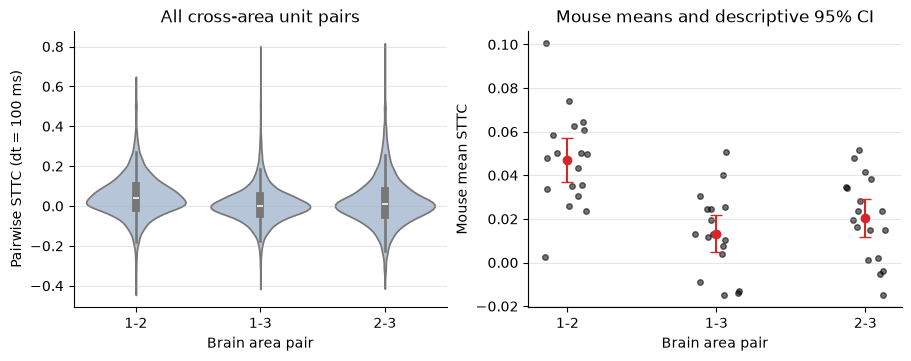

,mean_sttc,sd_mouse_means,n_mice,n_pairs,sem_sttc,ci95_low_sttc,ci95_high_sttc
area_pair,,,,,,,
1-2,0.047152,0.021960,18,18560,0.005176,0.037008,0.057297
1-3,0.013247,0.018298,18,11598,0.004313,0.004794,0.021701
2-3,0.020496,0.019152,18,9167,0.004514,0.011648,0.029344


In [4]:
mouse_summary = pairs.groupby(['mouse_id', 'area_pair'], as_index=False).agg(
    mean_sttc=('sttc', 'mean'), median_sttc=('sttc', 'median'),
    sd_sttc=('sttc', 'std'), n_pairs=('sttc', 'size'),
)
area_summary = mouse_summary.groupby('area_pair').agg(
    mean_sttc=('mean_sttc', 'mean'), sd_mouse_means=('mean_sttc', 'std'),
    n_mice=('mouse_id', 'size'), n_pairs=('n_pairs', 'sum'),
)
area_summary['sem_sttc'] = area_summary['sd_mouse_means'] / np.sqrt(area_summary['n_mice'])
ci_margin = 1.96 * area_summary['sem_sttc']
area_summary['ci95_low_sttc'] = area_summary['mean_sttc'] - ci_margin
area_summary['ci95_high_sttc'] = area_summary['mean_sttc'] + ci_margin
write_csv(mouse_summary, 'sttc_mouse_area_pair_100ms.csv')
write_csv(area_summary.reset_index(), 'sttc_area_pair_100ms.csv')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), layout='constrained')
positions = np.arange(len(PAIR_LABELS))
sns.violinplot(
    data=pairs, x='area_pair', y='sttc', order=PAIR_LABELS,
    cut=0, density_norm='width', color='lightsteelblue', ax=axes[0],
)
axes[0].set(xlabel='Brain area pair', ylabel='Pairwise STTC (dt = 100 ms)',
            title='All cross-area unit pairs')
jitter = np.random.default_rng(0)
for position, label in zip(positions, PAIR_LABELS):
    means = mouse_summary.loc[mouse_summary['area_pair'] == label, 'mean_sttc']
    axes[1].scatter(position + jitter.uniform(-0.15, 0.15, len(means)), means,
                    color='black', alpha=0.55, s=16)
axes[1].errorbar(
    positions, area_summary.loc[PAIR_LABELS, 'mean_sttc'],
    yerr=ci_margin.loc[PAIR_LABELS], fmt='o', color='tab:red', markersize=6, capsize=4,
)
axes[1].set(xlabel='Brain area pair', ylabel='Mouse mean STTC',
            title='Mouse means and descriptive 95% CI')
axes[1].set_xticks(positions, PAIR_LABELS)
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
fig.savefig(output_dir / 'sttc_100ms_by_area_pair.png', dpi=200, bbox_inches='tight')
plt.show()
display(area_summary)